## Pipeline 1 : IT Support Query Classifier

### Steps

1. **Unicode normalization**  
   Convert special characters like —, …, → into normal ASCII text

2. **Abbreviation expansion**  
   Convert short forms to full words  
   Example: acct → account, emial → email, 2fa → two factor authentication

3. **Contraction expansion**  
   Convert contractions to full form  
   Example: can't → cannot, won't → will not

4. **Digit / time tagging**  
   Replace numbers and time expressions with tags  
   Example: 48 hours → [TIME_EXPR], numbers → [QUANTITY]

5. **Remove punctuation**  
   Remove unnecessary symbols but keep useful ones like hyphens and tags

6. **Lowercasing**  
   Convert all text to lowercase

7. **Stopword removal**  
   Remove common words, but keep important ones like "not", "what", etc.

8. **Stemming**  
   Reduce words to root form  
   Example: tracking, tracked → track


---

### Models Used
- Logistic Regression

### Vectorization
- TF-IDF with word unigrams and bigrams

In [1]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn nltk scipy
import nltk
for pkg in ['punkt','stopwords','wordnet','punkt_tab']:
    nltk.download(pkg, quiet=True)

In [2]:
DATA_PATH = '/content/cw_data (1).csv'

print("Using file at:", DATA_PATH)

Using file at: /content/cw_data (1).csv


#Imports

In [3]:
import re, csv, warnings, unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.dpi'] = 110

# Main model we are focusing on is LR
PIPELINE_TITLE = 'Stemming + TF-IDF (word n-grams) + Logistic Regression'

# Function to safely display text containing < > without hiding content in notebooks (as observed)
def escape_tags(s):
    return str(s).replace('<', '[').replace('>', ']')

def escape_df(frame, cols=None):
    d = frame.copy()
    cols = cols if cols else d.select_dtypes('object').columns
    for c in cols:
        d[c] = d[c].apply(escape_tags)
    return d

# Initialize stemmer
stemmer = SnowballStemmer("english")

#Load & Explore Dataset

In [4]:
#=========================================================================================
# Basic Overview of the dataset
#=========================================================================================
import csv, pandas as pd, matplotlib.pyplot as plt

# Load CSV data into DataFrame
df = pd.DataFrame(
    [{'text': r[0].strip(), 'label': r[1].strip()}
     for r in csv.reader(open(DATA_PATH, encoding='utf-8')) if len(r) >= 2]
)

# Basic stats
total_samples = len(df)
num_classes   = df['label'].nunique()
avg_wc        = df['text'].str.split().str.len().mean()

# Print stats
print(f"Total samples: {total_samples}")
print(f"Number of classes: {num_classes}")
print(f"Average word count: {avg_wc:.3f}")
# quick check of text length (just to understand how short these queries are)
df['length'] = df['text'].apply(lambda x: len(str(x).split()))
print("Min length:", df['length'].min())
print("Max length:", df['length'].max())

Total samples: 308
Number of classes: 14
Average word count: 6.672
Min length: 3
Max length: 17


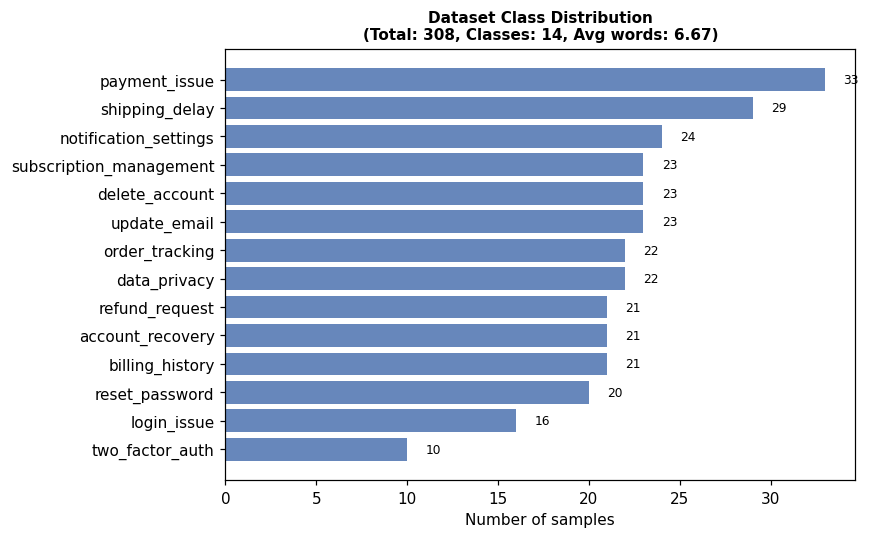

In [5]:
#dataset class distribution
# Value counts
vc = df['label'].value_counts().sort_values()

# Minimal horizontal bar chart
plt.figure(figsize=(8,5))
bars = plt.barh(vc.index, vc.values, color='#4C72B0', alpha=0.85)

# Annotate counts on bars
for bar in bars:
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'{int(bar.get_width())}', va='center', fontsize=8)

plt.title(f'Dataset Class Distribution\n(Total: {total_samples}, Classes: {num_classes}, Avg words: {avg_wc:.2f})',
          fontsize=10, fontweight='bold')
plt.xlabel('Number of samples')
plt.tight_layout()
plt.show()

In [6]:
# Display a few random sample records to check columns
print(df[['text','label']].sample(5, random_state=1))

                                                  text  \
73            cancel subscription early — lose access?   
304                 track international orders France?   
228  How do I change my 2FA method from SMS to an a...   
238                  payment processing error help pls   
259  Can I login from multiple devices at the same ...   

                       label  
73   subscription_management  
304           order_tracking  
228          two_factor_auth  
238            payment_issue  
259              login_issue  


## Preprocessing - Step by Step

**Note on [TIME_EXPR] / [QUANTITY]:**  
In the actual dataset, these are stored using angle brackets like `<TIME_EXPR>`.  
However, in the display tables, they are shown as `[TIME_EXPR]` so they remain visible.  
This is because browsers may treat `<TIME_EXPR>` as an HTML tag and hide it.  
The original data is not changed.

## Step 1: Unicode Normalisation

In [7]:
# I start by importing the unicodedata library to help normalize text into a standard Unicode form
import unicodedata

# I define a mapping for common special Unicode characters that often appear in text data.
# These include fancy quotes, dashes, accented characters, and symbols that I want to simplify.
UNICODE_MAP = {
    '\u2014': ' ', '\u2013': ' ',          # em dash, en dash → space
    '\u2026': ' ',                        # ellipsis → space
    '\u2018': "'", '\u2019': "'",          # curly single quotes → straight quote
    '\u201c': '"', '\u201d': '"',          # curly double quotes → straight quote
    '\u00e9': 'e', '\u00e8': 'e',          # accented e → e
    '\u00e0': 'a', '\u00fc': 'u',          # accented characters → base letters
    '\u00f6': 'o', '\u00e4': 'a',
    '\u2192': ' '                         # arrow symbol → space
}

# I create a function to normalize Unicode text into clean ASCII format
def normalise_unicode(text):
    # First, I replace known special characters using my predefined mapping
    for k, v in UNICODE_MAP.items():
        text = text.replace(k, v)

    # Then, I apply Unicode normalization (NFKD) to decompose accented characters
    text = unicodedata.normalize('NFKD', text)

    # Finally, I encode to ASCII and ignore any remaining unsupported characters
    return text.encode('ascii', 'ignore').decode('ascii')

# I apply the cleaning function to the 'text' column and store the result in a new column 'step1'
df['step1'] = df['text'].apply(normalise_unicode)

# I select a few sample rows to manually verify how the cleaning affected the text
sample_indices = [5, 6]

# I print the before-and-after comparison for these rows to check the transformation
for idx in sample_indices:
    before = df.loc[idx, 'text']
    after = df.loc[idx, 'step1']
    print(f"Row {idx}:\nBefore: {before}\nAfter : {after}\n{'-'*50}")

Row 5:
Before: email change fails… wat to do?
After : email change fails  wat to do?
--------------------------------------------------
Row 6:
Before: lost access email & phone — how 2 recover?
After : lost access email & phone   how 2 recover?
--------------------------------------------------


## Step 2: IT-Domain Abbreviation Expansion

In [8]:
import pandas as pd
import unicodedata
import re

# =========================
# Step 1: Unicode Normalization
# =========================
UNICODE_MAP = {
    '\u2014': ' ', '\u2013': ' ',
    '\u2026': ' ',
    '\u2018': "'", '\u2019': "'",
    '\u201c': '"', '\u201d': '"',
    '\u00e9': 'e', '\u00e8': 'e',
    '\u00e0': 'a', '\u00fc': 'u',
    '\u00f6': 'o', '\u00e4': 'a',
    '\u2192': ' '
}

def normalise_unicode(text):
    for k, v in UNICODE_MAP.items():
        text = text.replace(k, v)
    text = unicodedata.normalize('NFKD', text)
    return text.encode('ascii', 'ignore').decode('ascii')

# =========================
# Step 2: Expand Abbreviations
# =========================
ABBREV = {
    r'\bemial\b':'email', r'\bemil\b':'email',
    r'\b2fa\b':'two factor authentication', r'\b2-factor\b':'two factor',
    r'\bacct\b':'account',
    r'\bpls\b':'please', r'\bplz\b':'please',
    r'\bwat\b':'what', r'\bw8\b':'wait',
    r'\bthx\b':'thanks', r'\bthnx\b':'thanks',
    r'\bu\b':'you', r'\bur\b':'your',
    r'\bpwd\b':'password', r'\bpw\b':'password',
    r'\bauth\b':'authentication',
    r'\bnotif\b':'notification', r'\bnotifs\b':'notifications',
    r'\bprefs\b':'preferences', r'\bpref\b':'preference',
    r'\bsubs\b':'subscriptions',
    r'\binfo\b':'information', r'\btxn\b':'transaction',
    r'\bpmt\b':'payment', r'\binv\b':'invoice',
    r'\baddr\b':'address', r'\bdev\b':'device',
    r'\brecvd\b':'received', r'\bapprox\b':'approximately',
    r'\bconfig\b':'configuration',
    r'(?<!\w)1(?!\w)':'single', r'(?<!\w)2(?!\w)':'to'
}

def expand_abbrev(text):
    for k, v in ABBREV.items():
        text = re.sub(k, v, text, flags=re.IGNORECASE)
    return text

# =========================
# Step 3: Apply all steps
# =========================
df['step1'] = df['text'].apply(normalise_unicode)
df['step2'] = df['step1'].apply(expand_abbrev)

# =========================
# Step 4: Print specific samples (rows 0 and 2)
# =========================
for idx in [0, 2]:
    before = df.loc[idx, 'step1']
    after = df.loc[idx, 'step2']
    print(f"Row {idx}:\nBefore: {before}\nAfter : {after}\n{'-'*50}")

Row 0:
Before: tracking shows shipped but no delivery help pls
After : tracking shows shipped but no delivery help please
--------------------------------------------------
Row 2:
Before: invalid email entered wat happens?
After : invalid email entered what happens?
--------------------------------------------------


In [9]:
##this is data collected for report writing

import re
import unicodedata

# Informal shorthand detection
# Reusing ABBREV from previous steps
ABBREV_keys = ABBREV.keys()
informal_shorthand_pattern = re.compile(r'|'.join(ABBREV_keys), flags=re.IGNORECASE)

# Non-ASCII character detection
def contains_non_ascii(text):
    return any(ord(c) >= 128 for c in text)

# Counters
informal_shorthand_count = 0
non_ascii_count = 0

total_queries = len(df)

for index, row in df.iterrows():
    original_text = row['text']

    # Check for informal shorthands
    if informal_shorthand_pattern.search(original_text):
        informal_shorthand_count += 1

    # Check for non-ASCII characters
    if contains_non_ascii(original_text):
        non_ascii_count += 1

# Calculate percentages
informal_shorthand_percentage = (informal_shorthand_count / total_queries) * 100
non_ascii_percentage = (non_ascii_count / total_queries) * 100

print(f"Total queries: {total_queries}")
print(f"Queries with informal shorthand: {informal_shorthand_count} ({informal_shorthand_percentage:.1f}%)")
print(f"Queries with non-ASCII characters: {non_ascii_count} ({non_ascii_percentage:.1f}%)")

Total queries: 308
Queries with informal shorthand: 113 (36.7%)
Queries with non-ASCII characters: 56 (18.2%)


## Step 3: Contraction Expansion

In [10]:
# Step 3: Expand contractions (like "can't" to "cannot")
# I expand contractions to make the text more explicit and easier for the model to understand.
# This is especially important for negations like "not", which can completely change the meaning.
# For example, "can't login" and "can login" have opposite intents, so keeping that distinction clear matters.

CONTRACTIONS = {
    r"\bcan'?t\b":'cannot', r"\bwon'?t\b":'will not',
    r"\bdon'?t\b":'do not', r"\bdoesn'?t\b":'does not',
    r"\bdidn'?t\b":'did not', r"\bisn'?t\b":'is not',
    r"\baren'?t\b":'are not', r"\bwasn'?t\b":'was not',
    r"\bhadn'?t\b":'had not', r"\bhaven'?t\b":'have not',
    r"\bcouldn'?t\b":'could not', r"\bwouldn'?t\b":'would not',
    r"\bshouldn'?t\b":'should not',
    r"\bi'?m\b":'i am', r"\bi'?ve\b":'i have', r"\bi'?ll\b":'i will',
    r"\bi'?d\b":'i would', r"\bit'?s\b":'it is',
    r"\bthat'?s\b":'that is', r"\bwhat'?s\b":'what is', r"\bthere'?s\b":'there is'
}

def expand_contractions(text):
    for k, v in CONTRACTIONS.items():
        text = re.sub(k, v, text, flags=re.IGNORECASE)
    return text

# Apply contraction expansion
df['step3'] = df['step2'].apply(expand_contractions)

# Show only a few samples
changed = df[df['step2'] != df['step3']]

examples = changed[['text','step3']].head(2)
for i, row in examples.iterrows():
    print(f"Example {i+1}:")
    print("Before :", row['text'])
    print("After  :", row['step3'])

Example 41:
Before : cant pay with credit card immediately?
After  : cannot pay with credit card immediately?
Example 47:
Before : I'm unable to sign in — is this because my account is locked?
After  : i am unable to sign in   is this because my account is locked?


## Step 4: Digit / Temporal Semantic Tagging

In [34]:
# Convert numbers into semantic tags (<TIME_EXPR>, <QUANTITY>) instead of removing them.
# This keeps important context like duration ("2 days") and counts ("3 items"),
# which helps the model better understand user intent (e.g., delays, refunds, quantities).

NUMERIC_TAGS = {
    r'\b\d+\s*(hours?|hrs?|days?|months?|mos?|minutes?|mins?)\b': '<TIME_EXPR>',
    r'\b\d+\b': '<QUANTITY>'
}

def tag_numbers(text):
    for k, v in NUMERIC_TAGS.items():
        text = re.sub(k, v, text, flags=re.IGNORECASE)
    return text

df['step4'] = df['step3'].apply(tag_numbers)

# Find changed rows
changed = df[df['step3'] != df['step4']]

print(f"Changed rows: {len(changed)}/{len(df)}\n")

# Show 2 clear examples with reasoning
examples = changed[['text','step3','step4']].head(2)

for i, row in examples.iterrows():
    print(f"Example {i+1}:")
    print("Before :", row['step3'])
    print("After  :", row['step4'])

    if '<TIME_EXPR>' in row['step4']:
        print("Reason : Time-related number converted to <TIME_EXPR> to preserve duration context.")
    elif '<QUANTITY>' in row['step4']:
        print("Reason : Numeric value converted to <QUANTITY> to keep count information.\n")

    print("-" * 60)

Changed rows: 14/308

Example 127:
Before : shipping takes longer than expected within 48 hours
After  : shipping takes longer than expected within <TIME_EXPR>
Reason : Time-related number converted to <TIME_EXPR> to preserve duration context.
------------------------------------------------------------
Example 151:
Before : package not arrived within 48 hours what to do?
After  : package not arrived within <TIME_EXPR> what to do?
Reason : Time-related number converted to <TIME_EXPR> to preserve duration context.
------------------------------------------------------------


In [36]:
#Analyze the usage of `<TIME_EXPR>` tags
#Taken this data for report
time_expr_queries = df[df['processed'].str.contains('<time_expr>')]

num_time_expr_queries = len(time_expr_queries)
distinct_classes_with_time_expr = time_expr_queries['label'].nunique()

print(f"Number of queries with <TIME_EXPR> tags: {num_time_expr_queries}")
print(f"Distinct classes containing <TIME_EXPR> tags: {distinct_classes_with_time_expr}")

if num_time_expr_queries > 0:
    print("Classes with <TIME_EXPR> tags:")
    for class_name, count in time_expr_queries['label'].value_counts().items():
        print(f"- {class_name}: {count} queries")

Number of queries with <TIME_EXPR> tags: 14
Distinct classes containing <TIME_EXPR> tags: 6
Classes with <TIME_EXPR> tags:
- shipping_delay: 4 queries
- reset_password: 2 queries
- subscription_management: 2 queries
- refund_request: 2 queries
- payment_issue: 2 queries
- login_issue: 2 queries


## Step 5: Punctuation Stripping

In [12]:
# Step 5: Punctuation stripping
# Removes unnecessary punctuation while keeping intra-word hyphens (like "two-factor")
# and tags (<TIME_EXPR>, <QUANTITY>) so they remain meaningful for TF-IDF.

def strip_noise(text):
    # Keep hyphens inside words and angle brackets; remove other punctuation
    text = re.sub(r'[^\w\s\-<>]', ' ', text)
    text = re.sub(r'(?<!\w)-|-(?!\w)', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['step5'] = df['step4'].apply(strip_noise)

# Select affected queries with meaningful changes
changed = df[df['step4'] != df['step5']]

# check examples
examples = changed[
    changed['step5'].str.contains(r'\w-\w|<TIME_EXPR>|<QUANTITY>', regex=True)
].head(3)

for i, row in examples.iterrows():
    print(f"Example {i+1}:")
    print("Before:", row['step4'])
    print("After :", row['step5'])
    print("Reason : Removed noise but preserved hyphens and tags so meaningful tokens remain.\n")

Example 42:
Before: subscription auto-renewal turned off   verify?
After : subscription auto-renewal turned off verify
Reason : Removed noise but preserved hyphens and tags so meaningful tokens remain.

Example 84:
Before: Two-factor codes not working after changing devices; what next?
After : Two-factor codes not working after changing devices what next
Reason : Removed noise but preserved hyphens and tags so meaningful tokens remain.

Example 88:
Before: What happens if I disable two-factor authentication temporarily?
After : What happens if I disable two-factor authentication temporarily
Reason : Removed noise but preserved hyphens and tags so meaningful tokens remain.



## Step 6: Lowercase

In [13]:
# Step 6: Convert text to lowercase
# Reasoning: Lowercasing standardizes text so the model treats "Password" and "password" the same.

# Apply lowercase
df['step6'] = df['step5'].str.lower()

# Select queries that changed
was_mixed = df[df['step5'] != df['step6']]
print(f"Queries changed by lowercasing: {len(was_mixed)}/{len(df)}\n")
for i, row in was_mixed[['text','step5','step6']].head(3).iterrows():
    print(f"Example {i+1}:")
    print("Before :", row['step5'])
    print("After  :", row['step6'])
    print("Reason : Converted to lowercase for consistent token representation.\n")

Queries changed by lowercasing: 80/308

Example 9:
Before : access past bills France
After  : access past bills france
Reason : Converted to lowercase for consistent token representation.

Example 12:
Before : track international orders US
After  : track international orders us
Reason : Converted to lowercase for consistent token representation.

Example 13:
Before : Can I reset my password if my account is locked or do I need support
After  : can i reset my password if my account is locked or do i need support
Reason : Converted to lowercase for consistent token representation.



##  Step 7: Domain-Aware Stopword Removal

In [14]:
# Step 7: Domain-aware stopword removal
# Reasoning: Remove common English stopwords that add little meaning, but **keep negations and interrogatives**
# (like 'not', 'what', 'how') because they carry important IT classification signals.
# Also add domain-specific noise words (like 'pls', 'help') to FINAL_STOPS.

from nltk.corpus import stopwords

NLTK_STOPS = set(stopwords.words('english'))
KEEP_FROM_STOPS = {
    'no','not','without','can','cannot','why','how','what',
    'when','where','which','who','will','would','should',
    'does','do','did','after','before','if','is','are',
    'was','been','get','got','my','more','again','off',
}
EXTRA_STOPS = {'pls','help','please','possible','immediately','quickly','soon','later','also','wat','fix','steps','just'}

FINAL_STOPS = (NLTK_STOPS - KEEP_FROM_STOPS) | EXTRA_STOPS

def remove_stopwords(tokens):
    return [t for t in tokens if t not in FINAL_STOPS]

# Apply
df['step7_tokens'] = df['step6'].apply(lambda t: remove_stopwords(t.split()))
df['step7'] = df['step7_tokens'].apply(' '.join)

# Summary stats
print(f"NLTK stopwords total          : {len(NLTK_STOPS)}")
print(f"Words KEPT (signal words)     : {len(KEEP_FROM_STOPS)}")
print(f"Extra domain noise stops added: {len(EXTRA_STOPS)}")
print(f"Final stopword list size      : {len(FINAL_STOPS)}")
print(f"\nKept words: {sorted(KEEP_FROM_STOPS)}")

avg_before = df['step6'].apply(lambda t: len(t.split())).mean()
avg_after  = df['step7'].apply(lambda t: len(t.split())).mean()
print(f"\nAvg tokens per query: {avg_before:.1f} to {avg_after:.1f} (removed {avg_before-avg_after:.1f} tokens/query on average)\n")

# Show 2-3 clear examples with reasoning
examples = df[['text','step6','step7']].sample(3, random_state=5)
for i, row in examples.iterrows():
    print(f"Example {i+1}:")
    print("Before :", row['step6'])
    print("After  :", row['step7'])
    print("Reason : Removed generic stopwords while keeping negations, interrogatives, and domain-specific signal words.\n")

NLTK stopwords total          : 198
Words KEPT (signal words)     : 31
Extra domain noise stops added: 13
Final stopword list size      : 184

Kept words: ['after', 'again', 'are', 'been', 'before', 'can', 'cannot', 'did', 'do', 'does', 'get', 'got', 'how', 'if', 'is', 'more', 'my', 'no', 'not', 'off', 'should', 'was', 'what', 'when', 'where', 'which', 'who', 'why', 'will', 'without', 'would']

Avg tokens per query: 6.6 to 5.3 (removed 1.3 tokens/query on average)

Example 133:
Before : error deleting account what wrong
After  : error deleting account what wrong
Reason : Removed generic stopwords while keeping negations, interrogatives, and domain-specific signal words.

Example 228:
Before : if i reset my password will i be logged out of other devices
After  : if reset my password will logged devices
Reason : Removed generic stopwords while keeping negations, interrogatives, and domain-specific signal words.

Example 168:
Before : can delete account if active or need reactivate
After 

In [15]:
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer

# Define stemmers
stemmers = {
    'Porter': PorterStemmer(),
    'Snowball': SnowballStemmer('english'),
    'Lancaster': LancasterStemmer()
}

# Sample tokens
sample_tokens = df['step7_tokens'].explode().unique()
sample_tokens = [t for t in sample_tokens if not (t.startswith('<') and t.endswith('>'))]

# Stem each token with all stemmers
stem_results = {name: [stemmer.stem(t) for t in sample_tokens]
                for name, stemmer in stemmers.items()}

# Compare vocab sizes
for name, stems in stem_results.items():
    print(f"{name} stemmer vocab size: {len(set(stems))}")

# Show examples where stems differ
print("\nExample comparisons:")
for t in ['authentication', 'notification', 'password', 'subscriptions']:
    print(f"\nOriginal: {t}")
    for name, stemmer in stemmers.items():
        print(f"  {name} - {stemmer.stem(t)}")

Porter stemmer vocab size: 291
Snowball stemmer vocab size: 289
Lancaster stemmer vocab size: 281

Example comparisons:

Original: authentication
  Porter - authent
  Snowball - authent
  Lancaster - auth

Original: notification
  Porter - notif
  Snowball - notif
  Lancaster - not

Original: password
  Porter - password
  Snowball - password
  Lancaster - password

Original: subscriptions
  Porter - subscript
  Snowball - subscript
  Lancaster - subscrib


## SnowballStemmer

In [16]:
# Step 8: Controlled Stemming using SnowballStemmer
# Reasoning:
# - Porter stemmer was previously tested but over-aggressively reduced words,
#   often distorting IT terms critical for classification
# - SnowballStemmer provides more controlled stemming: it reduces words for TF-IDF sparsity
#   while preserving interpretability.
# - Semantic tags (<TIME_EXPR>, <QUANTITY>) are preserved to retain temporal/quantity information.
# - Short words (≤4 characters) are not stemmed to avoid distorting key tokens like "user", "code", "login".
# - Only longer, meaningful words are stemmed to reduce vocabulary and improve model efficiency.

from nltk.stem import SnowballStemmer

_stemmer = SnowballStemmer("english")

def stem_tokens(tokens):
    result = []
    for t in tokens:
        # Preserve semantic tags
        if t.startswith('<') and t.endswith('>'):
            result.append(t)
        # Stem longer words for dimensionality reduction
        elif len(t) > 4:
            result.append(_stemmer.stem(t))
        # Keep short words unchanged
        else:
            result.append(t)
    return result

# Apply controlled stemming
df['step8_tokens'] = df['step7_tokens'].apply(stem_tokens)
df['step8'] = df['step8_tokens'].apply(' '.join)

# Vocabulary analysis
vocab_before = set(tok for tokens in df['step7_tokens'] for tok in tokens)
vocab_after  = set(tok for tokens in df['step8_tokens'] for tok in tokens)

print(f"Vocabulary before stemming: {len(vocab_before)}")
print(f"Vocabulary after stemming : {len(vocab_after)}")
print(f"Reduction: {len(vocab_before)-len(vocab_after)} "
      f"({100*(len(vocab_before)-len(vocab_after))/len(vocab_before):.1f}%)\n")

# Showing examples of words grouped under the same stem
stem_groups = {}
for tok in vocab_before:
    if not (tok.startswith('<') and tok.endswith('>')):
        stem_groups.setdefault(_stemmer.stem(tok), set()).add(tok)

print("Sample words grouped under the same stem:")
interesting = sorted(
    [(s, w) for s, w in stem_groups.items() if len(w) > 1],
    key=lambda x: -len(x[1])
)

for stem, words in interesting[:10]:
    print(f'  "{stem}"  -  {sorted(words)}')

examples = df[['text','step7','step8']].sample(3, random_state=7)
for i, row in examples.iterrows():
    print(f"\nExample {i+1}:")
    print("Before :", row['step7'])
    print("After  :", row['step8'])


Vocabulary before stemming: 367
Vocabulary after stemming : 290
Reduction: 77 (21.0%)

Sample words grouped under the same stem:
  "fail"  -  ['fail', 'failed', 'failing', 'fails']
  "delet"  -  ['delete', 'deletes', 'deleting', 'deletion']
  "secur"  -  ['secure', 'securely', 'security']
  "updat"  -  ['update', 'updates', 'updating']
  "work"  -  ['work', 'working', 'works']
  "process"  -  ['process', 'processed', 'processing']
  "cancel"  -  ['cancel', 'canceled', 'cancelled']
  "chang"  -  ['change', 'changed', 'changing']
  "charg"  -  ['charge', 'charged', 'charges']
  "receiv"  -  ['receive', 'received', 'receiving']

Example 38:
Before : when refund processed
After  : when refund process

Example 171:
Before : cannot update email if account is active what do
After  : cannot updat email if account is activ what do

Example 257:
Before : order marked delivered not received
After  : order mark deliv not receiv


In [17]:
##Vocab/token check
vocab = set(t for s in df['step8'] for t in s.split())
print(f"Unique tokens: {len(vocab)}")
print(f"Avg tokens/query: {df['step8'].apply(lambda x: len(x.split())).mean():.2f}")

Unique tokens: 290
Avg tokens/query: 5.31


## FinalFull Pre-processing Summary: All 8 Steps Side by Side

In [18]:
def preprocess_stem(text):
    """Complete Pipeline 1 pre-processing (clean + controlled stemming).Fn calls one by one as show below"""

    text   = normalise_unicode(text)
    text   = expand_abbrev(text)
    text   = expand_contractions(text)
    text   = tag_numbers(text)
    text   = strip_noise(text)
    text   = text.lower()

    tokens = text.split()
    tokens = remove_stopwords(tokens)

    # Controlled stemming (Snowball-based)
    tokens = stem_tokens(tokens)

    return ' '.join(tokens)


# Apply preprocessing
df['processed'] = df['text'].apply(preprocess_stem)


#
showcase_indices = list(dict.fromkeys([
    df[df['text'].str.contains('\u2014')].index[0],
    df[df['text'].str.contains('\u2026')].index[0],
    df[df['text'].str.contains('acct', case=False)].index[0],
    df[df['text'].str.contains('emial', case=False)].index[0],
    df[df['text'].str.contains('2fa', case=False)].index[0],
    df[df['text'].str.contains('wat', case=False)].index[0],
    df[df['text'].str.contains("can't|won't|don't", case=False)].index[0],
    df[df['text'].str.contains('48 hour|24 hour', case=False)].index[0],
    df[df['text'].str.len() > 50].index[0],
]))[:12]

cols = ['text','step1','step2','step3','step4','step5','step6','step7','step8','label']

showcase = df.loc[showcase_indices, cols].copy()

showcase.columns = [
    'Raw',
    'Step1\nUnicode',
    'Step2\nAbbrev',
    'Step3\nContractions',
    'Step4\nNumeric',
    'Step5\nPunct',
    'Step6\nLower',
    'Step7\nStopwords',
    'Step8\nStemming',
    'Label'
]


# Display in table format
pd.set_option('display.max_colwidth', 40)

display(
    escape_df(showcase).reset_index(drop=True)
    .style.set_caption('All 8 Steps (Controlled Stemming)')
    .set_properties(**{'text-align':'left','font-size':'11px'})
)


# Final comparison print
print('\nRAW FINAL ONE')
print(f'{"RAW TEXT":<55}  {"FINAL PROCESSED":<50}  LABEL')
print('─'*120)

for _, row in showcase.reset_index().iterrows():
    final = escape_tags(row['Step8\nStemming'])
    print(f"  {row['Raw'][:53]:<55}  {final[:48]:<50}  {row['Label']}")

,Raw,Step1 Unicode,Step2 Abbrev,Step3 Contractions,Step4 Numeric,Step5 Punct,Step6 Lower,Step7 Stopwords,Step8 Stemming,Label
0,emial update failed error — fix?,emial update failed error fix?,email update failed error fix?,email update failed error fix?,email update failed error fix?,email update failed error fix,email update failed error fix,email update failed error,email updat fail error,update_email
1,email change fails… wat to do?,email change fails wat to do?,email change fails what to do?,email change fails what to do?,email change fails what to do?,email change fails what to do,email change fails what to do,email change fails what do,email chang fail what do,update_email
2,recover acct if suspended?,recover acct if suspended?,recover account if suspended?,recover account if suspended?,recover account if suspended?,recover account if suspended,recover account if suspended,recover account if suspended,recov account if suspend,account_recovery
3,2FA setup failed; can I try again later?,2FA setup failed; can I try again later?,two factor authentication setup failed; can I try again later?,two factor authentication setup failed; can I try again later?,two factor authentication setup failed; can I try again later?,two factor authentication setup failed can I try again later,two factor authentication setup failed can i try again later,two factor authentication setup failed can try again,two factor authent setup fail can try again,two_factor_auth
4,invalid email entered wat happens?,invalid email entered wat happens?,invalid email entered what happens?,invalid email entered what happens?,invalid email entered what happens?,invalid email entered what happens,invalid email entered what happens,invalid email entered what happens,invalid email enter what happen,update_email
5,Why can't I log into my account on my tablet?,Why can't I log into my account on my tablet?,Why can't I log into my account on my tablet?,Why cannot I log into my account on my tablet?,Why cannot I log into my account on my tablet?,Why cannot I log into my account on my tablet,why cannot i log into my account on my tablet,why cannot log my account my tablet,why cannot log my account my tablet,login_issue
6,shipping takes longer than expected within 48 hours,shipping takes longer than expected within 48 hours,shipping takes longer than expected within 48 hours,shipping takes longer than expected within 48 hours,shipping takes longer than expected within [TIME_EXPR],shipping takes longer than expected within [TIME_EXPR],shipping takes longer than expected within [time_expr],shipping takes longer expected within [time_expr],ship take longer expect within [time_expr],shipping_delay
7,Can I reset my password if my account is locked or do I need support?,Can I reset my password if my account is locked or do I need support?,Can I reset my password if my account is locked or do I need support?,Can I reset my password if my account is locked or do I need support?,Can I reset my password if my account is locked or do I need support?,Can I reset my password if my account is locked or do I need support,can i reset my password if my account is locked or do i need support,can reset my password if my account is locked do need support,can reset my password if my account is lock do need support,reset_password



RAW FINAL ONE
RAW TEXT                                                 FINAL PROCESSED                                     LABEL
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  emial update failed error — fix?                         email updat fail error                              update_email
  email change fails… wat to do?                           email chang fail what do                            update_email
  recover acct if suspended?                               recov account if suspend                            account_recovery
  2FA setup failed; can I try again later?                 two factor authent setup fail can try again         two_factor_auth
  invalid email entered wat happens?                       invalid email enter what happen                     update_email
  Why can't I log into my account on my tablet?            why cannot log my account my tablet                 login_issue

## Model - TF-IDF + Logistic Regression

Logistic Regression is the primary reported classifier.

### Build Logistic Regression Model & Train/Test Split


In [19]:
# Primary model: Logistic Regression
# I use Logistic Regression as the only reported model so that any performance
# difference between Pipeline 1 and Pipeline 2 is due purely to preprocessing,
# not changes in the model itself.

def build_model():
    # I use TF-IDF with unigrams and bigrams to capture both individual words and short phrases
    tfidf = TfidfVectorizer(
        analyzer='word', ngram_range=(1,2), sublinear_tf=True,
        min_df=1, max_df=0.90, max_features=8000,  # I tried min_df=2, but performance dropped, so I kept it at 1
        token_pattern=r'(?u)\b\w[\w\-<>]*\b',
        strip_accents=None,
    )

    # I configure Logistic Regression for multi-class classification
    lr = LogisticRegression(
        solver='lbfgs', multi_class='multinomial',
        C=1.0, class_weight='balanced',
        max_iter=1000, random_state=42,
    )

    return Pipeline([('tfidf', tfidf), ('clf', lr)])


# -------------------------
# Data Preparation
# -------------------------
X       = df['processed'].values
y       = df['label'].values
classes = sorted(df['label'].unique())

# I split the data into training and testing sets using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f'Train: {len(X_train)}  Test: {len(X_test)}  Classes: {len(classes)}')

# -------------------------
# Model Training
# -------------------------
model = build_model()
model.fit(X_train, y_train)

# I check the size of the learned vocabulary
print(f'TF-IDF vocab size : {len(model.named_steps["tfidf"].vocabulary_)}')

print('Logistic Regression model trained.')

Train: 246  Test: 62  Classes: 14
TF-IDF vocab size : 981
Logistic Regression model trained.


In [41]:
#baseline classifier
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier(strategy='stratified', random_state=42)
dummy_clf.fit(X_train, y_train)
dummy_pred = dummy_clf.predict(X_test)

baseline_f1_macro = f1_score(y_test, dummy_pred, average='macro')

print(f"Baseline Macro F1 (Dummy Classifier - stratified): {baseline_f1_macro:.3f}")

Baseline Macro F1 (Dummy Classifier - stratified): 0.083


## Test Set Classification Report Logistic Regression


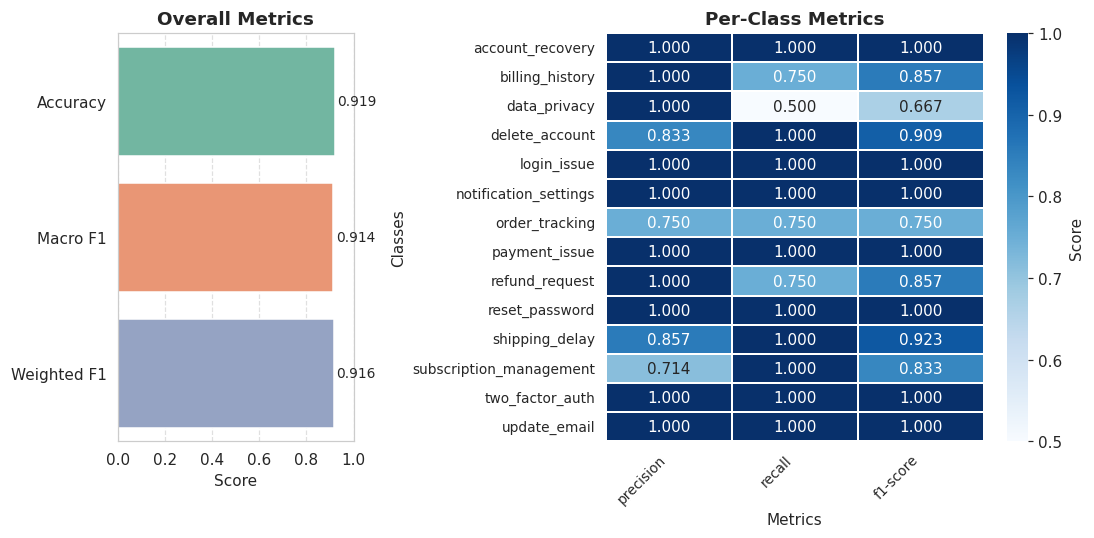

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report

# ===========================
# Predict and Compute Metrics
# ===========================
y_pred = model.predict(X_test)

acc     = accuracy_score(y_test, y_pred)
f1_mac  = f1_score(y_test, y_pred, average='macro')
f1_wt   = f1_score(y_test, y_pred, average='weighted')
report  = classification_report(y_test, y_pred, output_dict=True)

# Per-class metrics DataFrame
report_df = pd.DataFrame(report).T.drop(['accuracy'], errors='ignore')
report_df = report_df[report_df.index.isin(classes)].astype(float).round(3)

# ===========================
#  Figure
# ===========================
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios':[1,2]})

# Overall Metrics
metrics = pd.Series([acc, f1_mac, f1_wt], index=['Accuracy', 'Macro F1', 'Weighted F1'])
sns.barplot(x=metrics.values, y=metrics.index, palette="Set2", ax=axes[0], orient='h')
axes[0].set_xlim(0, 1)
axes[0].set_title('Overall Metrics', fontsize=12, weight='bold')
axes[0].set_xlabel('Score', fontsize=10)
axes[0].set_ylabel('')
axes[0].grid(axis='x', linestyle='--', alpha=0.6)

# Annotate bars
for i, v in enumerate(metrics.values):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va='center', fontsize=9)

#Per-Class Heatmap ---
sns.heatmap(
    report_df[['precision','recall','f1-score']],
    annot=True, fmt=".3f",
    cmap='Blues', vmin=0.5, vmax=1.0,
    linewidths=0.3, linecolor='white',
    cbar_kws={'label':'Score'},
    ax=axes[1]
)
axes[1].set_title('Per-Class Metrics', fontsize=12, weight='bold')
axes[1].set_ylabel('Classes', fontsize=10)
axes[1].set_xlabel('Metrics', fontsize=10)
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=9)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

In [21]:
# ===========================
# In detail display over console
# ===========================

# Overall Metrics
print("="*60)
print("         TEST SET RESULTS - Logistic Regression")
print("="*60)
print(f"Accuracy    : {acc:.4f}")
print(f"Macro F1    : {f1_mac:.4f}")
print(f"Weighted F1 : {f1_wt:.4f}")
print("="*60)
print()

# Per-Class Metrics
print("Per-Class Metrics:")
per_class_df = report_df[['precision','recall','f1-score']].copy()
print(per_class_df.to_string(float_format="{:.3f}".format))
print("="*60)

         TEST SET RESULTS - Logistic Regression
Accuracy    : 0.9194
Macro F1    : 0.9140
Weighted F1 : 0.9157

Per-Class Metrics:
                         precision  recall  f1-score
account_recovery             1.000   1.000     1.000
billing_history              1.000   0.750     0.857
data_privacy                 1.000   0.500     0.667
delete_account               0.833   1.000     0.909
login_issue                  1.000   1.000     1.000
notification_settings        1.000   1.000     1.000
order_tracking               0.750   0.750     0.750
payment_issue                1.000   1.000     1.000
refund_request               1.000   0.750     0.857
reset_password               1.000   1.000     1.000
shipping_delay               0.857   1.000     0.923
subscription_management      0.714   1.000     0.833
two_factor_auth              1.000   1.000     1.000
update_email                 1.000   1.000     1.000


## Confusion Matrix for Logistic Regression


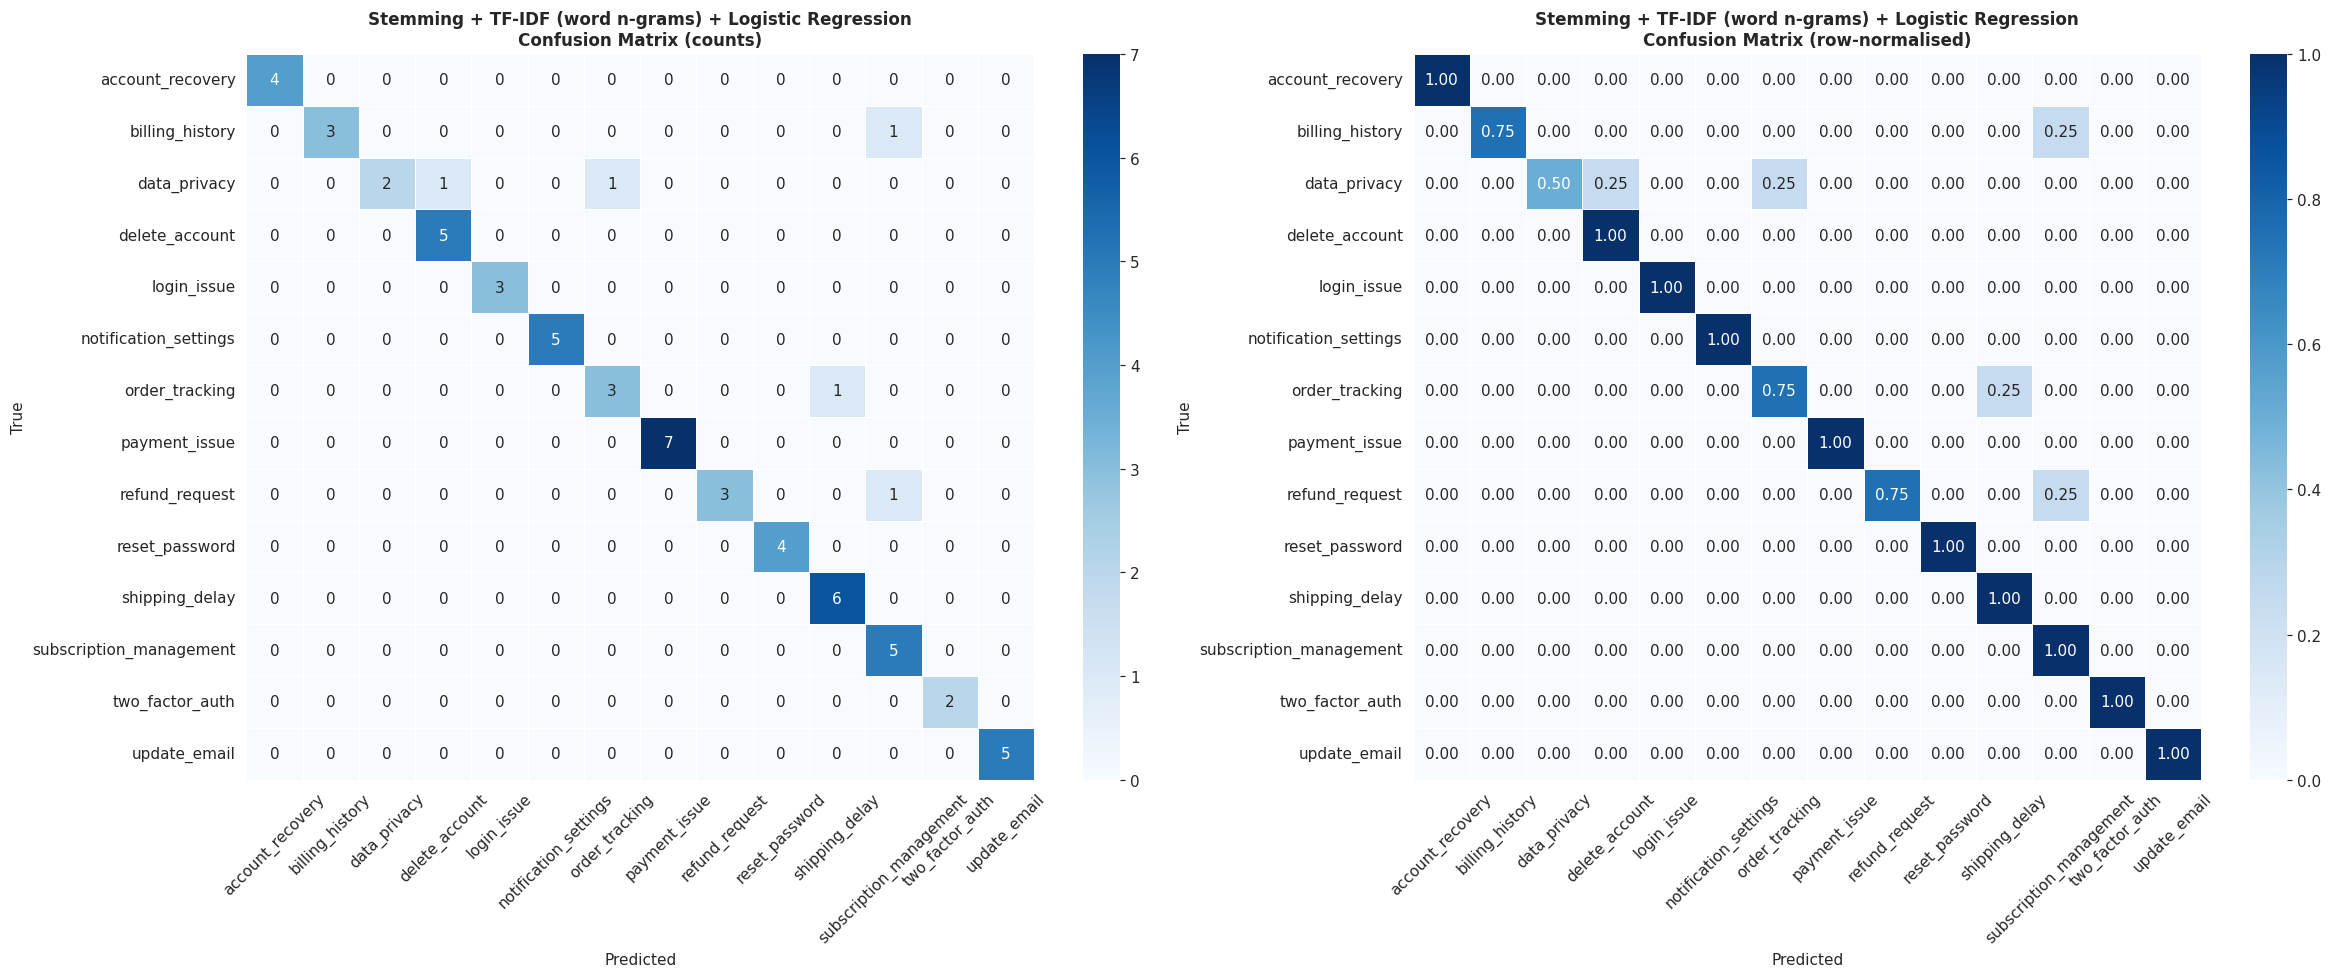

In [22]:
cm      = confusion_matrix(y_test, y_pred, labels=classes)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, data, fmt, sfx in zip(axes,[cm,cm_norm],['d','.2f'],['(counts)','(row-normalised)']):
    sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=classes, yticklabels=classes, linewidths=0.4, ax=ax)
    ax.set_title(f'{PIPELINE_TITLE}\nConfusion Matrix {sfx}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()


## Per-Class P/R/F1 Bar Chart Logistic Regression


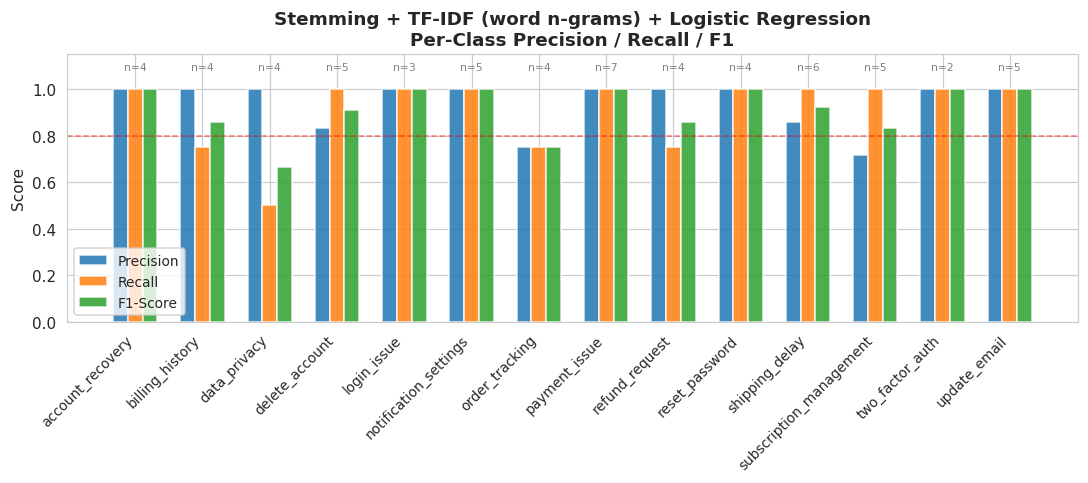

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Extract per-class metrics
cls_list  = [k for k in report if k not in ('accuracy','macro avg','weighted avg')]
precision = [report[c]['precision'] for c in cls_list]
recall    = [report[c]['recall']    for c in cls_list]
f1        = [report[c]['f1-score']  for c in cls_list]
support   = [report[c]['support']   for c in cls_list]

# Setup positions
x = np.arange(len(cls_list))
width = 0.22  # narrower bars

# Create figure
fig, ax = plt.subplots(figsize=(10, 4.5))  # smaller figure


colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Precision, Recall, F1

# Plot bars
ax.bar(x - width, precision, width, label='Precision', color=colors[0], alpha=0.85)
ax.bar(x,       recall,    width, label='Recall',    color=colors[1], alpha=0.85)
ax.bar(x + width, f1,      width, label='F1-Score',  color=colors[2], alpha=0.85)

# Labels and aesthetics
ax.set_xticks(x)
ax.set_xticklabels(cls_list, rotation=45, ha='right', fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', fontsize=10)
ax.set_title(f'{PIPELINE_TITLE}\nPer-Class Precision / Recall / F1', fontsize=12, fontweight='bold')

# Horizontal reference line
ax.axhline(0.8, color='red', linestyle='--', lw=1, alpha=0.5)

# Annotate support above bars
for i, sup in enumerate(support):
    ax.text(x[i], 1.08, f'n={int(sup)}', ha='center', fontsize=7, color='grey')

# Legend
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 5 Fold Cross-Validation Logistic Regression


5-fold stratified cross-validation - Logistic Regression
  Fold  Accuracy  Macro F1  Weighted F1
Fold 1    0.7742    0.7461       0.7594
Fold 2    0.9677    0.9598       0.9677
Fold 3    0.9355    0.9361       0.9348
Fold 4    0.9344    0.9319       0.9335
Fold 5    0.8525    0.8403       0.8491
  Mean    0.8929    0.8829       0.8889
   Std    0.0705    0.0796       0.0757


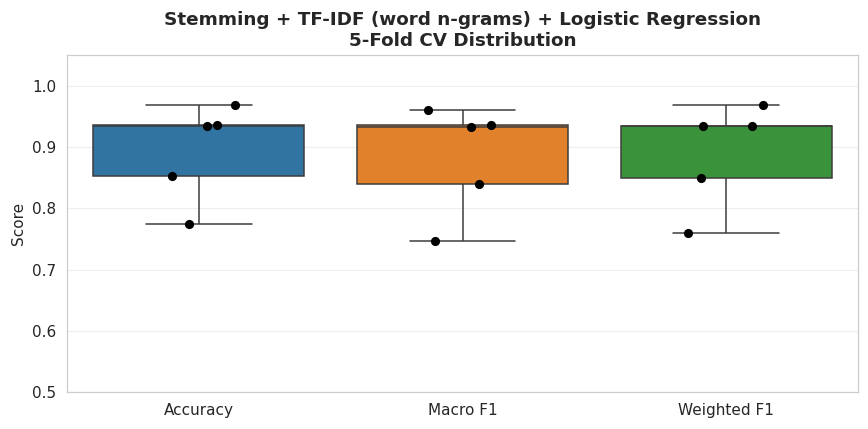

In [24]:
# -------------------------
# 5-Fold Stratified Cross-Validation - Logistic Regression
# -------------------------
# I use 5-fold cross-validation to get a more reliable estimate of how well my model performs.
# Instead of relying on a single train-test split, I divide the data into 5 equal parts (folds).
# The model is trained on 4 folds and tested on the remaining one, repeating this process 5 times.
# This helps me:
# - reduce the impact of random data splits
# - make better use of limited data (each sample is used for both training and testing)
# - check if the model is stable across different subsets of data
# I specifically chose 5 folds because it provides a good balance between performance reliability
# and computational cost (more folds = more time).

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate

# -------------------------
# 5-Fold Stratified Cross-Validation - Logistic Regression
# -------------------------
print('5-fold stratified cross-validation - Logistic Regression')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(
    build_model(), X, y, cv=cv,
    scoring={'accuracy':'accuracy','f1_macro':'f1_macro','f1_weighted':'f1_weighted'},
    return_train_score=True, n_jobs=-1
)

# -------------------------
# Prepare DataFrame for summary
# -------------------------
cv_df = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(5)],
    'Accuracy': cv_res['test_accuracy'].round(4),
    'Macro F1': cv_res['test_f1_macro'].round(4),
    'Weighted F1': cv_res['test_f1_weighted'].round(4),
})
cv_df.loc['Mean'] = ['Mean', cv_res['test_accuracy'].mean().round(4),
                     cv_res['test_f1_macro'].mean().round(4),
                     cv_res['test_f1_weighted'].mean().round(4)]
cv_df.loc['Std']  = ['Std',  cv_res['test_accuracy'].std().round(4),
                     cv_res['test_f1_macro'].std().round(4),
                     cv_res['test_f1_weighted'].std().round(4)]

# dislay details
print(cv_df.reset_index(drop=True).to_string(index=False))

# -------------------------
# CV Distribution Plot
# -------------------------
sns.set_style("whitegrid")
metrics = ['Accuracy', 'Macro F1', 'Weighted F1']
cv_values = [cv_res['test_accuracy'], cv_res['test_f1_macro'], cv_res['test_f1_weighted']]

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=cv_values, palette=['#1f77b4','#ff7f0e','#2ca02c'], ax=ax)
sns.stripplot(data=cv_values, color='black', size=6, jitter=0.15, ax=ax)  # smaller points

ax.set_xticklabels(metrics, fontsize=10)
ax.set_ylim(0.5, 1.05)
ax.set_ylabel('Score', fontsize=10)
ax.set_title(f'{PIPELINE_TITLE}\n5-Fold CV Distribution', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Learning Curve - Logistic Regression


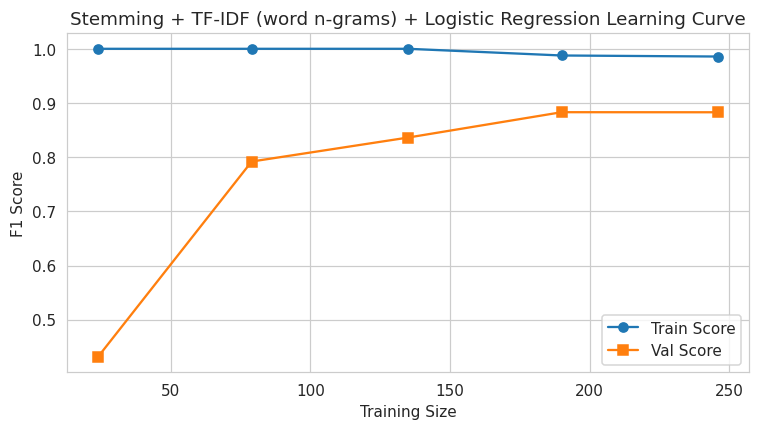

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold

# 1. Compute
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tr_sz, tr_sc, vl_sc = learning_curve(
    build_model(), X, y, cv=cv, scoring='f1_macro', n_jobs=-1
)

# 2. Plot
plt.figure(figsize=(8, 4))
plt.plot(tr_sz, tr_sc.mean(1), 'o-', label='Train Score')
plt.plot(tr_sz, vl_sc.mean(1), 's-', label='Val Score')

# 3. Label
plt.title(f'{PIPELINE_TITLE} Learning Curve')
plt.xlabel('Training Size')
plt.ylabel('F1 Score')
plt.legend()
plt.show()

## Prediction Confidence Histogram Logistic Regression


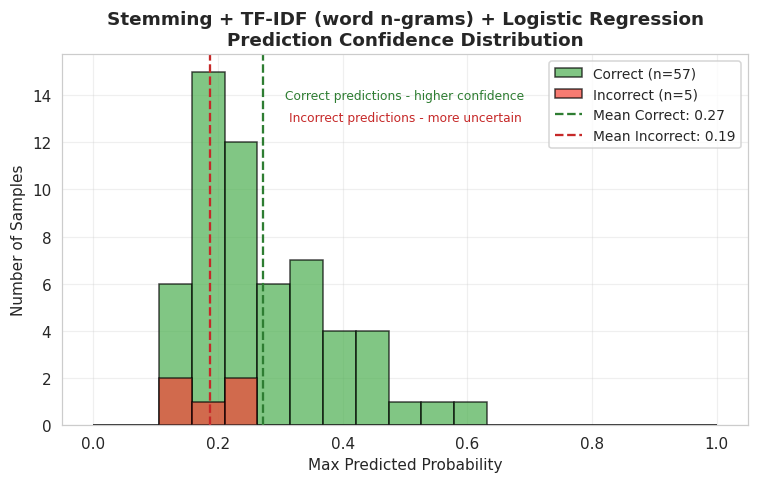

Mean confidence - Correct   : 0.273
Mean confidence - Incorrect : 0.188


In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Prediction probabilities
probas   = model.predict_proba(X_test)
max_prob = probas.max(axis=1)
correct  = y_pred == y_test

# -------------------------
#  Histogram
# -------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))  # smaller, compact figure
bins = np.linspace(0, 1, 20)

# Plot histograms
ax.hist(max_prob[correct],  bins=bins, alpha=0.7, color='#4CAF50', edgecolor='black',
        label=f'Correct (n={correct.sum()})')
ax.hist(max_prob[~correct], bins=bins, alpha=0.7, color='#F44336', edgecolor='black',
        label=f'Incorrect (n={(~correct).sum()})')

# Vertical lines for mean confidence
ax.axvline(max_prob[correct].mean(), color='#2E7D32', linestyle='--', linewidth=1.5,
           label=f'Mean Correct: {max_prob[correct].mean():.2f}')
ax.axvline(max_prob[~correct].mean(), color='#C62828', linestyle='--', linewidth=1.5,
           label=f'Mean Incorrect: {max_prob[~correct].mean():.2f}')

# Labels & title
ax.set_xlabel('Max Predicted Probability', fontsize=10)
ax.set_ylabel('Number of Samples', fontsize=10)
ax.set_title(f'{PIPELINE_TITLE}\nPrediction Confidence Distribution', fontsize=12, fontweight='bold')

# Insightful annotations
ylim = ax.get_ylim()
ax.text(0.5, ylim[1]*0.88, 'Correct predictions - higher confidence', color='#2E7D32', fontsize=8, ha='center')
ax.text(0.5, ylim[1]*0.82, 'Incorrect predictions - more uncertain', color='#C62828', fontsize=8, ha='center')

ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print mean confidence
print(f'Mean confidence - Correct   : {max_prob[correct].mean():.3f}')
print(f'Mean confidence - Incorrect : {max_prob[~correct].mean():.3f}')

## Top TF-IDF Features per Class Logistic Regression


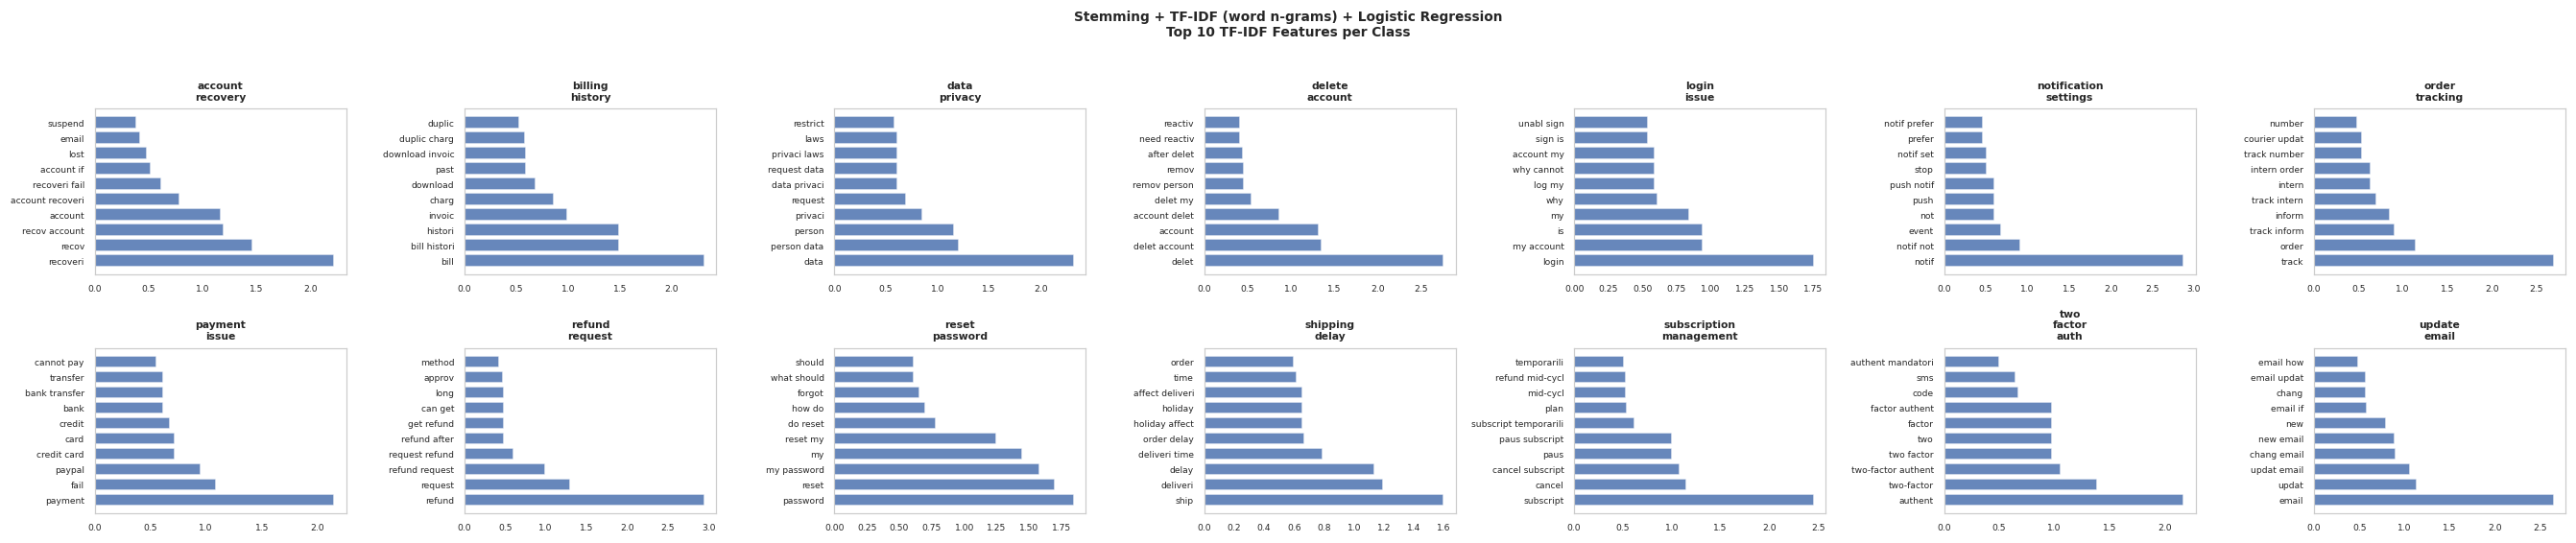

In [27]:
# -----------------------------
#visualization of top TF-IDF features per class
# - Extracts LR coefficients from pipeline
# - Plots top N features for each class in horizontal bars
# - Optimized for compactness: smaller figure, tighter layout, smaller fonts, minimal grid
# -----------------------------

# Extract LR coefficients and feature names
lr_clf     = model.named_steps['clf']
tfidf      = model.named_steps['tfidf']
coef       = lr_clf.coef_
feat_names = np.array(tfidf.get_feature_names_out())

top_n = 10                     # Number of top features per class
ncols = 7                       # Number of columns in subplot grid
nrows = int(np.ceil(len(classes)/ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*3.5, nrows*2.5))  # smaller figure
axes = axes.flatten()

for idx, cls in enumerate(classes):
    # Get indices of top features for the current class
    top_idx = np.argsort(coef[idx])[-top_n:][::-1]

    ax = axes[idx]
    ax.barh(range(top_n), coef[idx][top_idx][::-1], color='#4C72B0', alpha=0.85)
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(feat_names[top_idx][::-1], fontsize=6)  # smaller font
    ax.set_title(cls.replace('_','\n'), fontsize=7, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(False)  # minimal grid for compactness
    ax.tick_params(axis='x', labelsize=6)

# Hide unused axes
for j in range(len(classes), len(axes)):
    axes[j].set_visible(False)

# Main title
fig.suptitle(f'{PIPELINE_TITLE}\nTop {top_n} TF-IDF Features per Class',
             fontsize=9, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ===========================
# Results Table: Logistic Regression
# ===========================

lr_df = pd.DataFrame([{
    'Classifier':         'Logistic Regression',
    'Test Accuracy':      round(acc,     4),
    'Test Macro F1':      round(f1_mac,  4),
    'Test Weighted F1':   round(f1_wt,   4),
    'CV Acc (mean)':      round(cv_res['test_accuracy'].mean(),  4),
    'CV Macro F1 (mean)': round(cv_res['test_f1_macro'].mean(),  4),
    'CV Macro F1 (std)':  round(cv_res['test_f1_macro'].std(),   4),
}])

print('Logistic Regression Performance - Pipeline 1')
print(lr_df.to_string(index=False))

Logistic Regression Performance - Pipeline 1
         Classifier  Test Accuracy  Test Macro F1  Test Weighted F1  CV Acc (mean)  CV Macro F1 (mean)  CV Macro F1 (std)
Logistic Regression         0.9194          0.914            0.9157         0.8929              0.8829             0.0796


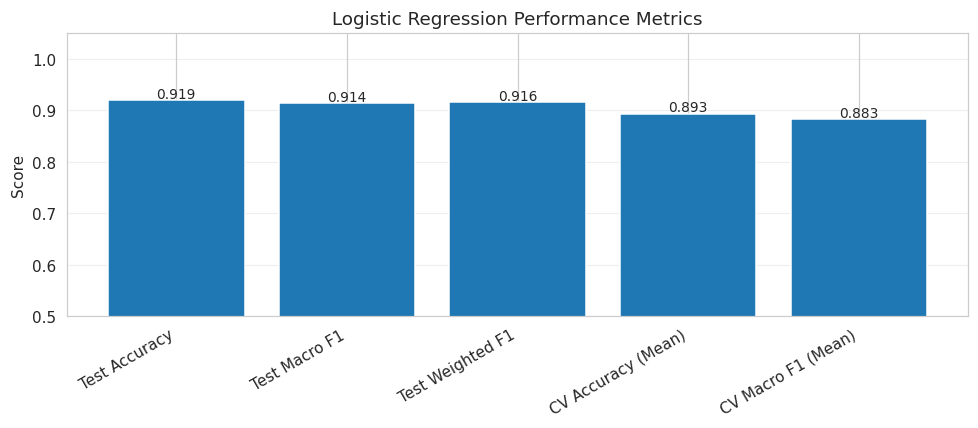

In [29]:
# ===========================
# Bar Chart: LR Metrics
# ===========================

metrics_labels = [
    'Test Accuracy',
    'Test Macro F1',
    'Test Weighted F1',
    'CV Accuracy (Mean)',
    'CV Macro F1 (Mean)'
]

lr_vals = [
    acc,
    f1_mac,
    f1_wt,
    cv_res['test_accuracy'].mean(),
    cv_res['test_f1_macro'].mean()
]

x = np.arange(len(metrics_labels))

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(x, lr_vals)

# annotate values
for i, val in enumerate(lr_vals):
    ax.text(i, val + 0.005, f"{val:.3f}", ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics_labels, rotation=30, ha='right')
ax.set_ylim(0.5, 1.05)
ax.set_ylabel('Score')
ax.set_title('Logistic Regression Performance Metrics')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# ===========================
# Cross-validation breakdown
# ===========================

cv_scores = cv_res['test_f1_macro']

print("\nCross-validation Macro F1 scores:", np.round(cv_scores, 4))
print("Mean:", round(np.mean(cv_scores), 4))
print("Std :", round(np.std(cv_scores), 4))


Cross-validation Macro F1 scores: [0.7461 0.9598 0.9361 0.9319 0.8403]
Mean: 0.8829
Std : 0.0796


In [31]:
# ===========================
# Error Analysis
# ===========================

errors = [
    (text, pred, true)
    for text, pred, true in zip(X_test, y_pred, y_test)
    if pred != true
]

print("\nTotal misclassifications:", len(errors))

for e in errors[:5]:
    print("\nText :", e[0])
    print("Pred :", e[1])
    print("True :", e[2])


Total misclassifications: 5

Text : track status pend ship what do
Pred : shipping_delay
True : order_tracking

Text : subscript payment histori
Pred : subscription_management
True : billing_history

Text : refund after subscript cancel
Pred : subscription_management
True : refund_request

Text : who access my inform intern
Pred : order_tracking
True : data_privacy

Text : delet my data perman
Pred : delete_account
True : data_privacy


## Consolidated Graphs


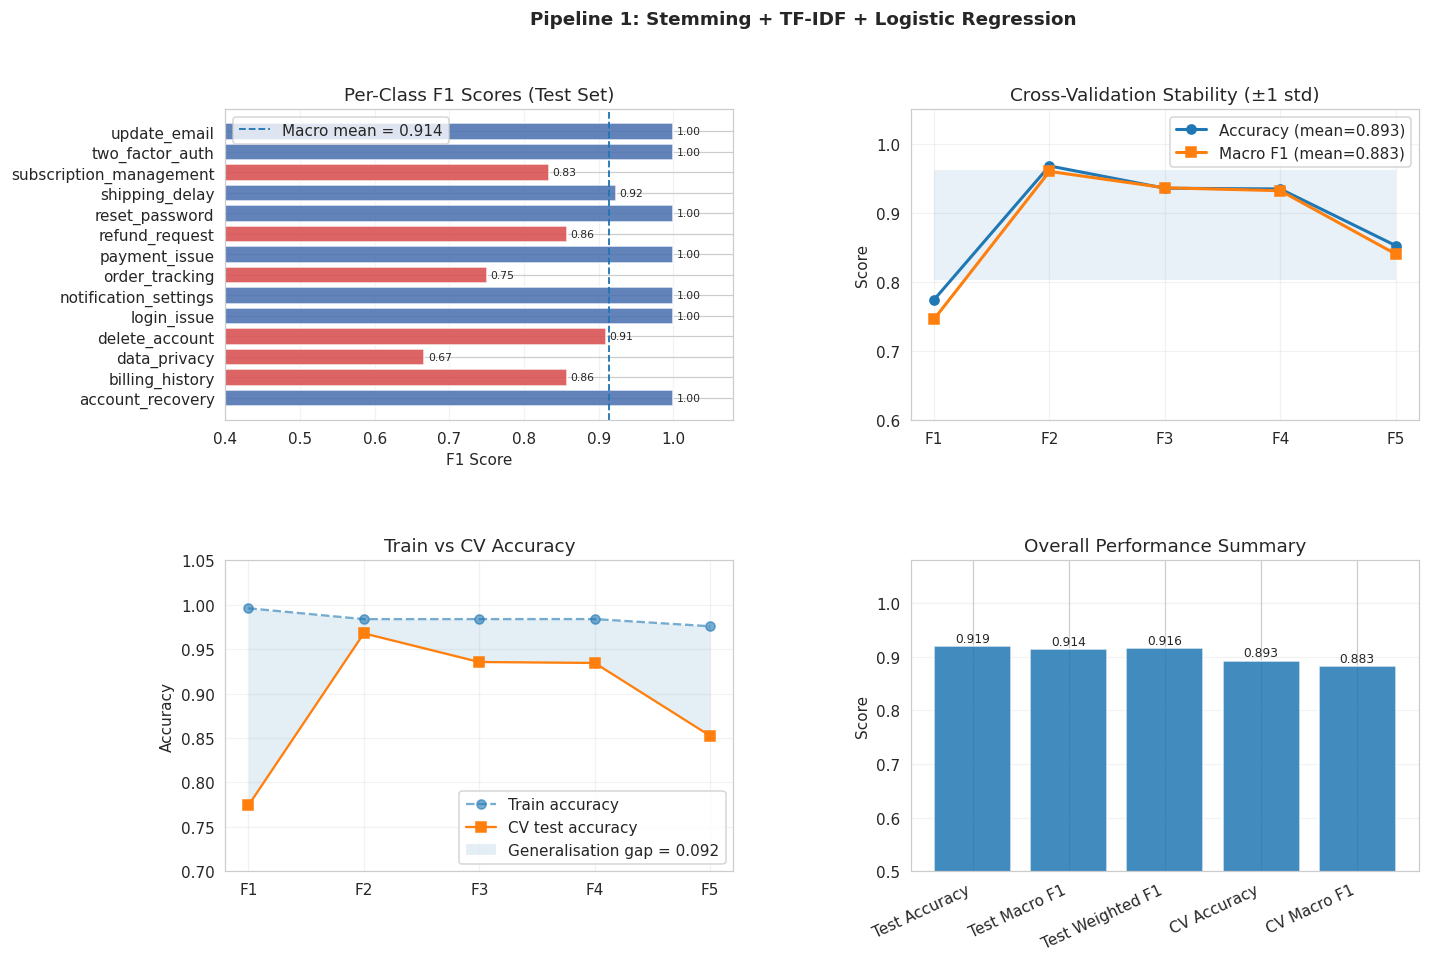

Saved: pipeline1_summary.png


In [32]:
# ===========================
# Pipeline 1  Summary
# ===========================
# Requires: cv_res, report, acc, f1_mac, f1_wt from above

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# ---------------------------
# Panel 1: Per-class F1
# ---------------------------
ax1 = fig.add_subplot(gs[0, 0])

cls_list = [k for k in report if k not in ('accuracy','macro avg','weighted avg')]
f1_vals  = [report[c]['f1-score'] for c in cls_list]
macro_m  = np.mean(f1_vals)

colors = ['#d94f4f' if v < macro_m else '#4C72B0' for v in f1_vals]

bars = ax1.barh(cls_list, f1_vals, color=colors, alpha=0.88)

ax1.axvline(macro_m, linestyle='--', linewidth=1.2,
            label=f'Macro mean = {macro_m:.3f}')

ax1.set_xlim(0.4, 1.08)
ax1.set_xlabel('F1 Score')
ax1.set_title('Per-Class F1 Scores (Test Set)')

ax1.legend()
ax1.grid(axis='x', alpha=0.25)

for bar, v in zip(bars, f1_vals):
    ax1.text(v + 0.005,
             bar.get_y() + bar.get_height()/2,
             f'{v:.2f}',
             va='center',
             fontsize=7)

# ---------------------------
# Panel 2: CV Stability
# ---------------------------
ax2 = fig.add_subplot(gs[0, 1])

folds = [f'F{i+1}' for i in range(5)]
x = np.arange(5)

acc_vals = cv_res['test_accuracy']
f1m_vals = cv_res['test_f1_macro']

ax2.plot(x, acc_vals, 'o-', linewidth=2,
         label=f'Accuracy (mean={acc_vals.mean():.3f})')

ax2.plot(x, f1m_vals, 's-', linewidth=2,
         label=f'Macro F1 (mean={f1m_vals.mean():.3f})')

ax2.fill_between(x,
                 f1m_vals.mean()-f1m_vals.std(),
                 f1m_vals.mean()+f1m_vals.std(),
                 alpha=0.1)

ax2.set_xticks(x)
ax2.set_xticklabels(folds)
ax2.set_ylim(0.6, 1.05)

ax2.set_ylabel('Score')
ax2.set_title('Cross-Validation Stability (±1 std)')

ax2.legend()
ax2.grid(alpha=0.25)

# ---------------------------
# Panel 3: Train vs CV Gap
# ---------------------------
ax3 = fig.add_subplot(gs[1, 0])

tr_acc = cv_res['train_accuracy']
te_acc = cv_res['test_accuracy']

ax3.plot(x, tr_acc, 'o--', alpha=0.6, label='Train accuracy')
ax3.plot(x, te_acc, 's-', label='CV test accuracy')

gap = tr_acc.mean() - te_acc.mean()

ax3.fill_between(x, te_acc, tr_acc, alpha=0.12,
                 label=f'Generalisation gap = {gap:.3f}')

ax3.set_xticks(x)
ax3.set_xticklabels(folds)
ax3.set_ylim(0.7, 1.05)

ax3.set_ylabel('Accuracy')
ax3.set_title('Train vs CV Accuracy')

ax3.legend()
ax3.grid(alpha=0.25)

# ---------------------------
# Panel 4: Summary Metrics
# ---------------------------
ax4 = fig.add_subplot(gs[1, 1])

metric_names = [
    'Test Accuracy',
    'Test Macro F1',
    'Test Weighted F1',
    'CV Accuracy',
    'CV Macro F1'
]

metric_vals = [
    acc,
    f1_mac,
    f1_wt,
    cv_res['test_accuracy'].mean(),
    cv_res['test_f1_macro'].mean()
]

x2 = np.arange(len(metric_names))

bars4 = ax4.bar(x2, metric_vals, alpha=0.85)

ax4.set_xticks(x2)
ax4.set_xticklabels(metric_names, rotation=25, ha='right')
ax4.set_ylim(0.5, 1.08)

ax4.set_ylabel('Score')
ax4.set_title('Overall Performance Summary')

for bar, v in zip(bars4, metric_vals):
    ax4.text(bar.get_x() + bar.get_width()/2,
             v + 0.008,
             f'{v:.3f}',
             ha='center',
             fontsize=8)

ax4.grid(axis='y', alpha=0.25)

# ---------------------------
# Title
# ---------------------------
fig.suptitle(
    'Pipeline 1: Stemming + TF-IDF + Logistic Regression',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('pipeline1_summary.png', dpi=160, bbox_inches='tight')
plt.show()

print("Saved: pipeline1_summary.png")